# BT4012 Fraud Analytics Group 14: RGCN

## Loading libraries

In [1]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve, confusion_matrix
from sklearn.preprocessing import RobustScaler

## Configuration

In [2]:
ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
GRAPH_DIR = PROCESSED / "graph"
OUT_DIR = ROOT / "results"

DROP_RELATIONS = ["shared_related_org"]
KEEP_RELATIONS = ["related_party_transaction", "shared_related_unlisted_firm", "org_investor_and_related_party", "unlisted_investment_and_related_party"]
CLIP = None
RGCN_KW = dict(n_layers=2, skip=True)

HIDDEN = 64
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### GraphSMOTE: setup


In [3]:
GSMOTE_KW = dict(hidden=HIDDEN, dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                 max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED,
                 up_scale=1.0,      # synthetic frauds per real training fraud (1.0 doubles them)
                 edge_weight=0.1,   # weight of the edge-reconstruction loss
                 warmup=20,         # epochs before synthesis starts
                 k_max=700,         # max edges per synthetic node per relation; lower it if GPU memory runs out
                 syn_to_real=True)  # real nodes also receive messages from synthetic nodes
GS_MODELS = ("gsmote", "ens_gsmote", "ens_all")
mlp_full_p = {}   # filled by the walk-forward loop: MLP scores for every node, per split
rgcn_full_p = {}  # same for the RGCN, for the MLP + RGCN + GraphSMOTE ensemble

## Hardware

In [4]:
torch.set_num_threads(8)

print(f"python {platform.python_version()} | torch {torch.__version__} | CUDA build {torch.version.cuda}")

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"running on {props.name}, {props.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available, running on CPU")

python 3.12.5 | torch 2.7.1+cu126 | CUDA build 12.6
running on NVIDIA GeForce RTX 3070, 8.6 GB


# Graph Construction

One graph per year for each split. Nodes are the company-years of that year, edges are that year's
company - company links. Train on the train-year graphs, then predict on the test-year graph.

Node features (merged on `nodeID` + `Year`):
1. Tabular features (`tabular_features_folds/split_<s>`)
2. Text features and text embeddings (same for all splits)
3. TF-IDF (`text_tfidf/split_<s>`)
4. Degree features saved above

Moved from `graph.ipynb`. Needs `graph_preprocessing.ipynb` and the feature notebooks to have been run first. Saves `graphs_split_<s>.pt` and `feature_cols.csv`, which the sections below load.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
from torch_geometric.data import Data
from sklearn.preprocessing import RobustScaler

c:\Users\Timothy\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
# fraud labels, used by the relation check below
df = pd.read_parquet("../data/processed/tabular_clean")

In [7]:
company_edges = pd.read_parquet("../data/processed/graph/company_edges.parquet")
degree_features = pd.read_csv("../data/processed/graph/degree_features.csv")
temporal_splits = pd.read_csv("../data/splits/temporal_splits.csv")
text_features = pd.read_parquet("../data/processed/text_features.parquet")
text_embeddings = pd.read_parquet("../data/processed/text_embeddings.parquet")

print("company_edges:  ", company_edges.shape)
print("degree_features:", degree_features.shape)
print("temporal_splits:", temporal_splits.shape)
print("text_features:  ", text_features.shape)
print("text_embeddings:", text_embeddings.shape)

company_edges:   (13157706, 4)
degree_features: (33634, 6)
temporal_splits: (105453, 5)
text_features:   (33664, 10)
text_embeddings: (33664, 66)


## Relation check
For each relation, the share of neighbours that are fraud, for fraud companies vs clean companies.
`lift` well above 1 means the relation is useful as an edge. Only 2014-2018 is used so no test year is looked at.

In [8]:
labels = df[["nodeID", "Year", "Label"]]

e = company_edges[company_edges["Year"] <= 2018]
e = e.merge(labels.rename(columns={"nodeID": "source_id", "Label": "source_label"}), on=["source_id", "Year"])
e = e.merge(labels.rename(columns={"nodeID": "target_id", "Label": "target_label"}), on=["target_id", "Year"])

relation_check = e.groupby(["relation", "source_label"])["target_label"].mean().unstack()
relation_check.columns = ["clean_company", "fraud_company"]
relation_check["lift"] = relation_check["fraud_company"] / relation_check["clean_company"]
relation_check.sort_values("lift", ascending=False).round(3)

,clean_company,fraud_company,lift
relation,,,
shared_related_unlisted_firm,0.037,0.072,1.934
related_party_transaction,0.042,0.073,1.759
org_investor_and_related_party,0.026,0.036,1.372
unlisted_investment_and_related_party,0.042,0.050,1.185
shared_auditor,0.048,0.052,1.099
shared_org_investor,0.037,0.041,1.096
shared_unlisted_investment,0.039,0.041,1.046
shared_individual_investor,0.055,0.057,1.033
shared_related_individual,0.053,0.051,0.969


## Choosing edges
All relations are kept except `shared_related_org` (51 links, no fraud company in 2014-2018).
Each relation is its own `edge_type` (0-11), so the RGCN learns a separate representation for each relation, and dense relations like `shared_auditor` are averaged on their own instead of drowning out the smaller ones.
The relation check above is kept for reference: it shows which relations are most linked to fraud.

In [9]:
drop_relations = ["shared_related_org"]   

graph_edges = company_edges[~company_edges["relation"].isin(drop_relations)].copy()
relation_list = sorted(graph_edges["relation"].unique())
relation_to_id = {r: i for i, r in enumerate(relation_list)}
graph_edges["edge_type"] = graph_edges["relation"].map(relation_to_id)

print(f"edges: {len(company_edges):,} -> {len(graph_edges):,}")
graph_edges.groupby(["edge_type", "relation"]).size()

edges: 13,157,706 -> 13,157,604


edge_type  relation                             
0          Investment                                141934
1          individual_investor_and_related_party      35128
2          org_investor_and_related_party              5468
3          related_party_transaction                  20890
4          shared_auditor                           8665326
5          shared_individual_investor                197878
6          shared_org_investor                       451376
7          shared_related_individual                 732956
8          shared_related_unlisted_firm               70146
9          shared_unlisted_investment               2757824
10         supply_chain_partner                        4716
11         unlisted_investment_and_related_party      73962
dtype: int64

## Node features for each split
Degree counts are log transformed, then scaled with a `RobustScaler` fitted on train rows only.

In [10]:
def get_node_features(s):
    rows = temporal_splits[temporal_splits["split"] == s]
    tabular = pd.read_parquet(f"../data/processed/tabular_features_folds/split_{s}")
    tfidf = pd.read_parquet(f"../data/processed/text_tfidf/split_{s}.parquet")

    features = rows.merge(tabular, on=["nodeID", "Year"], how="left")
    features = features.merge(text_features, on=["nodeID", "Year"], how="left")
    features = features.merge(text_embeddings, on=["nodeID", "Year"], how="left")
    features = features.merge(tfidf, on=["nodeID", "Year"], how="left")
    features = features.merge(degree_features, on=["nodeID", "Year"], how="left")

    # no row in degree_features means no edges
    deg_cols = ["n_Audit", "n_Investment", "n_Related-party transaction", "n_Supply chain"]
    features[deg_cols] = np.log1p(features[deg_cols].fillna(0))
    scaler = RobustScaler().fit(features.loc[features["role"] == "train", deg_cols])
    features[deg_cols] = scaler.transform(features[deg_cols])
    return features


features_0 = get_node_features(0)
feature_cols = [c for c in features_0.columns if c not in ["nodeID", "Year", "Label", "split", "role"]]
print("split 0 rows:", len(features_0))
print("features:", len(feature_cols))
print("missing values:", features_0[feature_cols].isna().sum().sum())

split 0 rows: 19494
features: 1414
missing values: 0


## Building the graph for each year

In [11]:
def build_graph(features, year):
    year_rows = features[features["Year"] == year].reset_index(drop=True)
    year_edges = graph_edges[graph_edges["Year"] == year]

    # nodeID -> row number in this year's graph
    node_index = {node: i for i, node in enumerate(year_rows["nodeID"])}
    src = year_edges["source_id"].map(node_index)
    dst = year_edges["target_id"].map(node_index)

    graph = Data(
        x=torch.tensor(year_rows[feature_cols].astype(float).values, dtype=torch.float),
        edge_index=torch.tensor(np.array([src.values, dst.values]), dtype=torch.long),
        edge_type=torch.tensor(year_edges["edge_type"].values, dtype=torch.long),
        y=torch.tensor(year_rows["Label"].values, dtype=torch.long),
    )
    graph.year = year
    graph.role = year_rows["role"].iloc[0]
    graph.node_ids = list(year_rows["nodeID"])
    return graph

In [12]:
all_graphs = {}
for s in range(4):
    features = get_node_features(s)
    all_graphs[s] = {}
    for year in sorted(features["Year"].unique()):
        all_graphs[s][int(year)] = build_graph(features, year)
    print(f"split {s}: graphs for {min(all_graphs[s])}-{max(all_graphs[s])}")

split 0: graphs for 2014-2019
split 1: graphs for 2014-2020
split 2: graphs for 2014-2021
split 3: graphs for 2014-2022


In [13]:
summary = []
for s, graphs in all_graphs.items():
    for year, g in graphs.items():
        summary.append({"split": s, "year": year, "role": g.role, "nodes": g.num_nodes,
                        "fraud": int(g.y.sum()), "edges": g.num_edges, "features": g.num_node_features})
pd.DataFrame(summary)

,split,year,role,nodes,fraud,edges,features
0,0,2014,train,2631,95,676824,1414
1,0,2015,train,2824,134,1563754,1414
2,0,2016,train,3125,173,1495632,1414
3,0,2017,train,3503,205,1273194,1414
4,0,2018,train,3596,225,1526722,1414
5,0,2019,test,3815,214,1266620,1414
6,1,2014,train,2631,95,676824,1414
7,1,2015,train,2824,134,1563754,1414
8,1,2016,train,3125,173,1495632,1414
9,1,2017,train,3503,205,1273194,1414


## Saving graph

In [14]:
for s, graphs in all_graphs.items():
    torch.save(graphs, f"../data/processed/graph/graphs_split_{s}.pt")
    print(f"saved graphs_split_{s}.pt")

pd.Series(feature_cols, name="feature").to_csv("../data/processed/graph/feature_cols.csv", index=False)
print("saved feature_cols.csv")

saved graphs_split_0.pt
saved graphs_split_1.pt
saved graphs_split_2.pt
saved graphs_split_3.pt
saved feature_cols.csv


## Splits, relations and feature blocks

In [15]:
splits = pd.read_csv(ROOT / "data" / "splits" / "temporal_splits.csv")
split_test_year = (splits[splits["role"] == "test"].groupby("split")["Year"].first().astype(int).to_dict())
TEST_YEARS = list(split_test_year.values())

all_relations = (pq.read_table(GRAPH_DIR / "company_edges.parquet", columns=["relation"]).column("relation").unique().to_pylist())
RELATIONS = sorted(r for r in all_relations if r not in DROP_RELATIONS)

feature_cols = pd.read_csv(GRAPH_DIR / "feature_cols.csv")["feature"].tolist()
text_cols = set()
for path in [PROCESSED / "text_features.parquet", PROCESSED / "text_embeddings.parquet", PROCESSED / "text_tfidf" / "split_0.parquet"]:
    text_cols |= set(pq.read_schema(path).names)
degree_cols = set(pd.read_csv(GRAPH_DIR / "degree_features.csv", nrows=0).columns)
BLOCK = np.array(["text" if c in text_cols else "degree" if c in degree_cols else "tabular" for c in feature_cols])
KEEP_RELATIONS = RELATIONS

print("test year per split:", split_test_year)
print(f"relations ({len(RELATIONS)}):", ", ".join(RELATIONS))
print(f"features ({len(feature_cols):,}):", pd.Series(BLOCK).value_counts().to_dict())

test year per split: {0: 2019, 1: 2020, 2: 2021, 3: 2022}
relations (12): Investment, individual_investor_and_related_party, org_investor_and_related_party, related_party_transaction, shared_auditor, shared_individual_investor, shared_org_investor, shared_related_individual, shared_related_unlisted_firm, shared_unlisted_investment, supply_chain_partner, unlisted_investment_and_related_party
features (1,414): {'tabular': 1238, 'text': 172, 'degree': 4}


## Data loading

In [16]:
def load_split(s: int):
    graphs = torch.load(GRAPH_DIR / f"graphs_split_{s}.pt", weights_only=False)
    xs, ids, years, labels, edge_index, edge_type = [], [], [], [], [], []
    offset = 0
    for yr in sorted(graphs):
        g = graphs[yr]
        xs.append(g.x)
        ids += list(g.node_ids)
        years.append(np.full(g.num_nodes, yr))
        labels.append(g.y.numpy())
        edge_index.append(g.edge_index + offset)
        edge_type.append(g.edge_type)
        offset += g.num_nodes

    nodes = pd.DataFrame({"nodeID": ids, "Year": np.concatenate(years), "Label": np.concatenate(labels)})
    X = torch.cat(xs).numpy()
    edge_index, edge_type = torch.cat(edge_index, dim=1), torch.cat(edge_type)

    expected = splits[splits["split"] == s]
    check = nodes.merge(expected, on=["nodeID", "Year"], how="left", suffixes=("", "_splits"))
    assert len(nodes) == len(expected), f"split {s}: node count differs from temporal_splits.csv"
    assert (check["Label"] == check["Label_splits"]).all(), f"split {s}: labels differ from temporal_splits.csv"
    assert nodes["Year"].max() == split_test_year[s], f"split {s}: last graph is not the test year"
    assert X.shape[1] == len(feature_cols), f"split {s}: feature count differs from feature_cols.csv"
    assert np.isfinite(X).all(), f"split {s}: features contain NaN or inf"
    assert int(edge_type.max()) < len(RELATIONS), "edge_type out of range; check DROP_RELATIONS"
    return nodes, X, edge_index, edge_type

def build_adjacency(edge_index, edge_type, n: int) -> list[torch.Tensor]:
    src, dst = edge_index
    adjs = []
    for r in range(len(RELATIONS)):
        m = edge_type == r
        i, j = dst[m], src[m]
        deg = torch.bincount(i, minlength=n).clamp(min=1).float()
        A = torch.sparse_coo_tensor(torch.stack([i, j]), 1.0 / deg[i], (n, n), check_invariants=False)
        adjs.append(A.coalesce().to(DEVICE))
    return adjs

def prepare_inputs(X: np.ndarray, fit_rows: np.ndarray) -> tuple[np.ndarray, dict]:
    X = X.copy()
    text = BLOCK == "text"
    X[:, text] = RobustScaler().fit(X[fit_rows][:, text]).transform(X[:, text])
    X = np.sign(X) * np.log1p(np.abs(X))

    clipped = {}
    if CLIP is not None:
        beyond = np.abs(X) > CLIP
        clipped = {b: float(beyond[:, BLOCK == b].mean()) for b in ("tabular", "text", "degree")}
        X = np.clip(X, -CLIP, CLIP)
    return X.astype(np.float32), clipped

def add_fraud_history(nodes: pd.DataFrame, X: np.ndarray) -> np.ndarray:
    """Append two columns: was this company fraud the year before (0 if not listed then),
    and was it listed the year before. Only labels from earlier years are used."""
    prev = (nodes[["nodeID", "Year", "Label"]]
            .assign(Year=nodes["Year"] + 1)
            .rename(columns={"Label": "prev_fraud"}))
    m = nodes[["nodeID", "Year"]].merge(prev, on=["nodeID", "Year"], how="left", validate="one_to_one")
    prev_fraud = m["prev_fraud"].fillna(0).to_numpy(np.float32)
    had_prev_year = m["prev_fraud"].notna().to_numpy(np.float32)
    return np.column_stack([X, prev_fraud, had_prev_year]).astype(np.float32)

### GraphSMOTE: raw graph
Unnormalised adjacency and degree per relation (count / degree gives the same row-normalised adjacency as `build_adjacency`), plus a helper for each year's node range.

In [17]:
def build_raw_graph(edge_index, edge_type, n, keep, device):
    src, dst = edge_index
    A, deg, edges = [], [], []
    for r in keep:
        m = edge_type == r
        i, j = dst[m], src[m]
        A.append(torch.sparse_coo_tensor(torch.stack([i, j]), torch.ones(len(i)), (n, n)).coalesce().to(device))
        deg.append(torch.bincount(i, minlength=n).float().to(device))
        edges.append(torch.stack([i, j]))
    return A, deg, edges


def _year_ranges(year: np.ndarray):
    uniq, first, counts = np.unique(year, return_index=True, return_counts=True)
    ranges = {}
    for y, s, c in zip(uniq.tolist(), first.tolist(), counts.tolist()):
        assert (year[s:s + c] == y).all(), "nodes of one year are not contiguous"
        ranges[int(y)] = (s, c)
    return ranges

## Model

In [18]:
class RGCNLayer(nn.Module):
    def __init__(self, d_in: int, d_out: int, n_rel: int):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.rel_lin = nn.ModuleList(nn.Linear(d_in, d_out, bias=False) for _ in range(n_rel))

    def forward(self, h, adjs):
        out = self.self_lin(h)
        for A, lin in zip(adjs, self.rel_lin):
            out = out + torch.sparse.mm(A, lin(h))
        return out

class RGCN(nn.Module):
    def __init__(self, d_in: int, n_rel: int, n_layers: int = 2, skip: bool = False):
        super().__init__()
        self.inp = nn.Linear(d_in, HIDDEN)
        self.convs = nn.ModuleList(RGCNLayer(HIDDEN, HIDDEN, n_rel) for _ in range(n_layers))
        self.skip = skip
        self.out = nn.Linear(HIDDEN * (n_layers + 1) if skip else HIDDEN, 1)
        self.drop = nn.Dropout(DROPOUT)

    def embed(self, x, adjs):
        h = self.drop(F.relu(self.inp(x)))
        hs = [h]
        for conv in self.convs:
            h = self.drop(F.relu(conv(h, adjs)))
            hs.append(h)
        return torch.cat(hs, dim=1) if self.skip else h

    def forward(self, x, adjs):
        return self.out(self.embed(x, adjs)).squeeze(1)

### GraphSMOTE: model
The same 2-layer RGCN with skip connections as above. The second layer also accepts weighted edges to synthetic nodes, and there is one bilinear edge generator per relation. With no synthetic nodes it gives the same outputs as `RGCN`.

In [19]:
class RelConv(nn.Module):
    def __init__(self, d_in, d_out, n_rel):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.rel_lin = nn.ModuleList(nn.Linear(d_in, d_out, bias=False) for _ in range(n_rel))

    def forward(self, h, A, deg, extra=None):
        n, N = A[0].shape[0], h.shape[0]
        out = self.self_lin(h)
        for r, lin in enumerate(self.rel_lin):
            z = lin(h)
            agg = torch.sparse.mm(A[r], z[:n])
            d = deg[r]
            if N > n:
                agg = torch.cat([agg, agg.new_zeros(N - n, agg.shape[1])])
                d = torch.cat([d, d.new_zeros(N - n)])
            if extra is not None:
                e_dst, e_src, e_w = extra[r]
                if len(e_dst):
                    agg = agg.index_add(0, e_dst, z[e_src] * e_w[:, None])
                    d = d.index_add(0, e_dst, e_w)
            d = torch.where(d > 0, d, torch.ones_like(d))
            out = out + agg / d[:, None]
        return out


class GraphSMOTERGCN(nn.Module):
    def __init__(self, d_in, n_rel, hidden=64, dropout=0.3):
        super().__init__()
        self.inp = nn.Linear(d_in, hidden)
        self.conv1 = RelConv(hidden, hidden, n_rel)  # encoder
        self.conv2 = RelConv(hidden, hidden, n_rel)  # classifier GNN (augmented graph)
        self.out = nn.Linear(3 * hidden, 1)
        self.edge_W = nn.Parameter(torch.eye(hidden).repeat(n_rel, 1, 1) / hidden ** 0.5)
        self.edge_b = nn.Parameter(torch.zeros(n_rel))
        self.drop = nn.Dropout(dropout)

    def encode(self, x, A, deg):
        h0 = self.drop(F.relu(self.inp(x)))
        h1 = self.drop(F.relu(self.conv1(h0, A, deg)))
        return h0, h1

    def head_embed(self, h0, h1, A, deg, extra=None):
        h2 = self.drop(F.relu(self.conv2(h1, A, deg, extra)))
        return torch.cat([h0, h1, h2], dim=1)

    def edge_logits(self, r, a, b):
        """Score of edge b -> a (a receives) for paired rows."""
        return ((a @ self.edge_W[r]) * b).sum(1) + self.edge_b[r]

    def edge_logits_matrix(self, r, a, b):
        """All-pairs scores, rows = receivers a, columns = senders b."""
        return (a @ self.edge_W[r]) @ b.T + self.edge_b[r]

    def embed(self, x, A, deg):
        h0, h1 = self.encode(x, A, deg)
        return self.head_embed(h0, h1, A, deg)

    def forward(self, x, A, deg):
        return self.out(self.embed(x, A, deg)).squeeze(1)

## Training

In [20]:
def scores(y, p):
    return roc_auc_score(y, p), average_precision_score(y, p)

def train_one(X, y, adjs, tr, va, n_rel, return_model=False, **model_kw):
    torch.manual_seed(SEED)
    model = RGCN(X.shape[1], n_rel, **model_kw).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    pos_weight = (y[tr] == 0).sum() / (y[tr] == 1).sum()
    y_np = y.cpu().numpy()
    
    history = []
    best_auc, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        opt.zero_grad()
        logits = model(X, adjs)
        loss = F.binary_cross_entropy_with_logits(logits[tr], y[tr], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(X, adjs)).cpu().numpy()
        val_auc = roc_auc_score(y_np[va.cpu().numpy()], p[va.cpu().numpy()])
        history.append({"epoch": epoch, "loss": loss.item(), "val_auc": val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, waited = val_auc, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(X, adjs)).cpu().numpy()
    hist = pd.DataFrame(history)
    return (p, best_auc, best_epoch, hist, model) if return_model else (p, best_auc, best_epoch, hist)

### GraphSMOTE: synthesis and training
Synthetic fraud nodes are made by interpolating each training fraud company with its nearest training fraud company from the same year, after the first RGCN layer. Each gets top-k edges per relation from the edge generator, with k taken from its parents' degrees. Synthetic nodes exist only during training; validation and test companies never see them. `train_graphsmote` works like `train_one`.

In [21]:
def _synthesise(model, h0, h1, deg, fraud_idx, year_t, ranges, up_scale, k_max, syn_to_real):
    n, dev = h1.shape[0], h1.device
    parents_i, parents_j = [], []
    for yv in torch.unique(year_t[fraud_idx]).tolist():
        idx = fraud_idx[year_t[fraud_idx] == yv]
        if len(idx) < 2:
            continue
        with torch.no_grad():
            dist = torch.cdist(h1[idx], h1[idx])
            dist.fill_diagonal_(float("inf"))
            nearest = idx[dist.argmin(1)]
        reps = int(up_scale)
        n_extra = int(round((up_scale - reps) * len(idx)))
        pick = torch.cat([torch.arange(len(idx), device=dev).repeat(reps),
                          torch.randperm(len(idx), device=dev)[:n_extra]])
        if len(pick):
            parents_i.append(idx[pick])
            parents_j.append(nearest[pick])
    if not parents_i:
        return None

    i, j = torch.cat(parents_i), torch.cat(parents_j)
    m = len(i)
    delta = torch.rand(m, 1, device=dev)
    h0s = h0[i] + delta * (h0[j] - h0[i])
    h1s = h1[i] + delta * (h1[j] - h1[i])
    ys = year_t[i]

    extra = []
    for r in range(len(deg)):
        k = (deg[r][i] + delta[:, 0] * (deg[r][j] - deg[r][i])).round().long().clamp(max=k_max)
        dsts, srcs, ws = [], [], []
        for yv in torch.unique(ys).tolist():
            sel = (ys == yv).nonzero().squeeze(1)
            start, size = ranges[int(yv)]
            K = min(int(k[sel].max()), size)
            if K == 0:
                continue
            logits = model.edge_logits_matrix(r, h1s[sel], h1[start:start + size])
            top_val, top_idx = logits.topk(K, dim=1)
            keep = torch.arange(K, device=dev)[None, :] < k[sel][:, None]
            syn = (n + sel)[:, None].expand(-1, K)[keep]
            real = (top_idx + start)[keep]
            w = torch.sigmoid(top_val[keep])
            dsts.append(syn); srcs.append(real); ws.append(w)
            if syn_to_real:
                dsts.append(real); srcs.append(syn); ws.append(w)
        if dsts:
            extra.append((torch.cat(dsts), torch.cat(srcs), torch.cat(ws)))
        else:
            empty = torch.empty(0, dtype=torch.long, device=dev)
            extra.append((empty, empty, torch.empty(0, device=dev)))
    return h0s, h1s, extra, m


def _edge_loss(model, h1, train_edges, start_t, size_t, batch):
    """Edge reconstruction: sampled real edges vs random same-year non-edges."""
    losses = []
    for r, (dst, src) in enumerate(train_edges):
        if len(dst) == 0:
            continue
        sel = torch.randint(len(dst), (min(batch, len(dst)),), device=dst.device)
        d, s = dst[sel], src[sel]
        neg = start_t[d] + (torch.rand(len(d), device=d.device) * size_t[d]).long()
        logits = torch.cat([model.edge_logits(r, h1[d], h1[s]), model.edge_logits(r, h1[d], h1[neg])])
        target = torch.cat([torch.ones(len(d), device=d.device), torch.zeros(len(d), device=d.device)])
        losses.append(F.binary_cross_entropy_with_logits(logits, target))
    return torch.stack(losses).mean() if losses else h1.new_zeros(())

In [22]:
def train_graphsmote(X, y, A, deg, edges, year, tr, va, *, hidden=64, dropout=0.3, lr=0.005,
                     weight_decay=5e-4, max_epochs=300, patience=30, seed=0,
                     up_scale=1.0, edge_weight=0.1, warmup=20, k_max=100, edge_batch=4096,
                     syn_to_real=True, reweight=True, return_model=False):
    torch.manual_seed(seed)
    dev = X.device
    n = X.shape[0]
    model = GraphSMOTERGCN(X.shape[1], len(A), hidden, dropout).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    ranges = _year_ranges(year)
    year_t = torch.tensor(year, device=dev)
    start_t = torch.tensor([ranges[int(v)][0] for v in year], device=dev)
    size_t = torch.tensor([ranges[int(v)][1] for v in year], device=dev, dtype=torch.float32)

    tr_np = tr.cpu().numpy()
    train_edges = []
    for e in edges:
        keep = torch.from_numpy(tr_np[e[0].numpy()])
        train_edges.append((e[0][keep].to(dev), e[1][keep].to(dev)))
    fraud_idx = (tr & (y == 1)).nonzero().squeeze(1)
    n_pos, n_neg = (y[tr] == 1).sum(), (y[tr] == 0).sum()
    pos_weight0 = n_neg / n_pos
    y_np, va_np = y.cpu().numpy(), va.cpu().numpy()

    history = []
    best_auc, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        opt.zero_grad()
        h0, h1 = model.encode(X, A, deg)
        syn = _synthesise(model, h0, h1, deg, fraud_idx, year_t, ranges, up_scale, k_max, syn_to_real) \
            if epoch > warmup else None

        if syn is None:
            m = 0
            logits = model.out(model.head_embed(h0, h1, A, deg)).squeeze(1)
            cls_loss = F.binary_cross_entropy_with_logits(logits[tr], y[tr], pos_weight=pos_weight0)
        else:
            h0s, h1s, extra, m = syn
            logits = model.out(model.head_embed(torch.cat([h0, h0s]), torch.cat([h1, h1s]), A, deg, extra)).squeeze(1)
            lt = torch.cat([logits[:n][tr], logits[n:]])
            yt = torch.cat([y[tr], torch.ones(m, device=dev)])
            pw = n_neg / (n_pos + m) if reweight else pos_weight0
            cls_loss = F.binary_cross_entropy_with_logits(lt, yt, pos_weight=pw)

        e_loss = _edge_loss(model, h1, train_edges, start_t, size_t, edge_batch)
        loss = cls_loss + edge_weight * e_loss
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(X, A, deg)).cpu().numpy()
        val_auc = roc_auc_score(y_np[va_np], p[va_np])
        history.append({"epoch": epoch, "loss": cls_loss.item(), "edge_loss": e_loss.item(),
                        "val_auc": val_auc, "n_synthetic": m})
        if epoch <= warmup:  # only keep checkpoints trained with synthetic nodes
            continue
        if val_auc > best_auc:
            best_auc, best_epoch, waited = val_auc, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(X, A, deg)).cpu().numpy()
    hist = pd.DataFrame(history)
    return (p, best_auc, best_epoch, hist, model) if return_model else (p, best_auc, best_epoch, hist)

In [23]:
emb = {}
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X_np, edge_index, edge_type = load_split(s)
    year, labels = nodes["Year"].to_numpy(), nodes["Label"].to_numpy()
    X_np, _ = prepare_inputs(X_np, fit_rows=year < test_year)
    X_np = X_np[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X_t = torch.tensor(add_fraud_history(nodes, X_np), device=DEVICE)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    y_t = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    p, val_auc, epoch, _, model = train_one(X_t, y_t, adjs, tr, va, len(adjs), return_model=True, **RGCN_KW)
    model.eval()
    with torch.no_grad():
        H = model.embed(X_t, adjs).cpu().numpy()

    emb[s] = {"H": H, "nodeID": nodes["nodeID"].to_numpy(), "year": year, "labels": labels, "p": p, "model": model}
    test = year == test_year
    print(f"split {s} ({test_year}): H {H.shape}, RGCN test AUC {roc_auc_score(labels[test], p[test]):.4f}")

    del X_t, y_t, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

split 0 (2019): H (19494, 192), RGCN test AUC 0.8545
split 1 (2020): H (23763, 192), RGCN test AUC 0.8203
split 2 (2021): H (28532, 192), RGCN test AUC 0.8427
split 3 (2022): H (33664, 192), RGCN test AUC 0.8803


In [24]:
EMB_DIR = PROCESSED / "rgcn_embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)
for s, e in emb.items():
    val_year = split_test_year[s] - 1
    info = pd.DataFrame({"nodeID": e["nodeID"],
                         "Year": e["year"],
                         "Label": e["labels"],
                         "role": np.select([e["year"] < val_year, e["year"] == val_year], ["train", "val"], "test"),
                         "rgcn_score": e["p"]})
    vecs = pd.DataFrame(e["H"], columns=[f"h{i}" for i in range(e["H"].shape[1])])
    pd.concat([info, vecs], axis=1).to_parquet(EMB_DIR / f"split_{s}.parquet", index=False)
    print(f"saved split {s}: {len(info):,} rows, {e['H'].shape[1]} hidden columns")

saved split 0: 19,494 rows, 192 hidden columns
saved split 1: 23,763 rows, 192 hidden columns
saved split 2: 28,532 rows, 192 hidden columns
saved split 3: 33,664 rows, 192 hidden columns


## Walk-forward experiments

In [25]:
rows, preds, histories, split_info = [], [], [], []
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X, edge_index, edge_type = load_split(s)
    year = nodes["Year"].to_numpy()
    labels = nodes["Label"].to_numpy()
    test_mask = year == test_year

    X, clipped = prepare_inputs(X, fit_rows=year < test_year)
    X = X[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X = add_fraud_history(nodes, X)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    adjs = [adjs[RELATIONS.index(r)] for r in KEEP_RELATIONS]
    n_edges = sum(A._nnz() for A in adjs)
    X = torch.tensor(X, device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    split_info.append({"split": s,
                       "test_year": test_year,
                       "nodes": len(nodes),
                       "edges": n_edges,
                       "features": X.shape[1],
                       "train_fraud": int(labels[year < val_year].sum()),
                       "val_fraud": int(labels[year == val_year].sum()),
                       "test_fraud": int(labels[test_mask].sum()),
                       **{f"clipped_{b}": v for b, v in clipped.items()}})
    print(f"split {s}: {len(nodes):,} nodes, {n_edges:,} edges, {X.shape[1]:,} features; "
          "values clipped: " + ", ".join(f"{b} {v:.2%}" for b, v in clipped.items()))

    p_by_model = {}
    for name, graph, kw in [("mlp", [], {}), ("rgcn", adjs, RGCN_KW)]:
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        p, val_auc, epoch, hist = train_one(X, y, graph, tr, va, len(graph), **kw)
        p_by_model[name] = p
        secs = time.perf_counter() - t0
        gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

        auc, ap = scores(labels[test_mask], p[test_mask])
        rows.append({"model": name,
                     "split": s,
                     "test_year": test_year,
                     "best_epoch": epoch,
                     "val_auc": val_auc,
                     "test_auc": auc,
                     "test_pr_auc": ap,
                     "test_fraud_rate": labels[test_mask].mean(),
                     "seconds": secs,
                     "peak_gpu_gb": gpu_gb})
        preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model=name, score=p[test_mask]))
        histories.append(hist.assign(model=name, test_year=test_year))
        print(f"  {name:<5} {test_year}  epoch {epoch:>3}  val {val_auc:.4f}  "
              f"test AUC {auc:.4f}  PR-AUC {ap:.4f}  {secs:.0f}s  {gpu_gb:.2f} GB")

    # GraphSMOTE >>> keep the MLP's and RGCN's scores for every node, for the GraphSMOTE ensembles
    mlp_full_p[s] = p_by_model["mlp"]
    rgcn_full_p[s] = p_by_model["rgcn"]
    # <<< GraphSMOTE

    # ensemble: the average of the MLP's and the RGCN's scores
    p = (p_by_model["mlp"] + p_by_model["rgcn"]) / 2
    val_mask = year == val_year
    auc, ap = scores(labels[test_mask], p[test_mask])
    rows.append({"model": "ens",
                 "split": s,
                 "test_year": test_year,
                 "best_epoch": np.nan,
                 "val_auc": roc_auc_score(labels[val_mask], p[val_mask]),
                 "test_auc": auc,
                 "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(),
                 "seconds": np.nan,
                 "peak_gpu_gb": np.nan})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="ens", score=p[test_mask]))
    print(f"  {'ens':<5} {test_year}  test AUC {auc:.4f}  PR-AUC {ap:.4f}")
    del X, y, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(rows).round(4)
preds_df = pd.concat(preds, ignore_index=True)
hist_df = pd.concat(histories, ignore_index=True)
split_info = pd.DataFrame(split_info)
print()
print(res.groupby("model")[["test_auc", "test_pr_auc"]].mean())

OUT_DIR.mkdir(exist_ok=True)
res.to_csv(OUT_DIR / "rgcn_results.csv", index=False)
preds_df.to_csv(OUT_DIR / "rgcn_predictions.csv", index=False)
res

split 0: 19,494 nodes, 7,802,746 edges, 729 features; values clipped: 
  mlp   2019  epoch  82  val 0.8924  test AUC 0.8704  PR-AUC 0.3339  1s  0.28 GB
  rgcn  2019  epoch  64  val 0.8791  test AUC 0.8550  PR-AUC 0.3231  11s  0.58 GB
  ens   2019  test AUC 0.8757  PR-AUC 0.3626
split 1: 23,763 nodes, 9,345,718 edges, 729 features; values clipped: 
  mlp   2020  epoch 182  val 0.9147  test AUC 0.8393  PR-AUC 0.3590  1s  0.33 GB
  rgcn  2020  epoch  57  val 0.8930  test AUC 0.8172  PR-AUC 0.2704  12s  0.70 GB
  ens   2020  test AUC 0.8349  PR-AUC 0.3420
split 2: 28,532 nodes, 11,163,822 edges, 729 features; values clipped: 
  mlp   2021  epoch  53  val 0.8613  test AUC 0.8304  PR-AUC 0.3092  1s  0.39 GB
  rgcn  2021  epoch  74  val 0.8707  test AUC 0.8428  PR-AUC 0.3092  16s  0.87 GB
  ens   2021  test AUC 0.8475  PR-AUC 0.3261
split 3: 33,664 nodes, 13,157,604 edges, 729 features; values clipped: 
  mlp   2022  epoch 164  val 0.8868  test AUC 0.8952  PR-AUC 0.3605  1s  0.46 GB
  rgcn  2

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,mlp,0,2019,82.0,0.8924,0.8704,0.3339,0.0561,0.7263,0.2769
1,rgcn,0,2019,64.0,0.8791,0.8550,0.3231,0.0561,10.9395,0.5764
2,ens,0,2019,NaN,0.8941,0.8757,0.3626,0.0561,NaN,NaN
3,mlp,1,2020,182.0,0.9147,0.8393,0.3590,0.0485,1.3404,0.3285
4,rgcn,1,2020,57.0,0.8930,0.8172,0.2704,0.0485,11.6273,0.7049
5,ens,1,2020,NaN,0.9113,0.8349,0.3420,0.0485,NaN,NaN
6,mlp,2,2021,53.0,0.8613,0.8304,0.3092,0.0384,0.6953,0.3908
7,rgcn,2,2021,74.0,0.8707,0.8428,0.3092,0.0384,16.2833,0.8664
8,ens,2,2021,NaN,0.8733,0.8475,0.3261,0.0384,NaN,NaN
9,mlp,3,2022,164.0,0.8868,0.8952,0.3605,0.0240,1.3359,0.4562


### Split summary

In [26]:
split_info

,split,test_year,nodes,edges,features,train_fraud,val_fraud,test_fraud
0,0,2019,19494,7802746,729,607,225,214
1,1,2020,23763,9345718,729,832,214,207
2,2,2021,28532,11163822,729,1046,207,183
3,3,2022,33664,13157604,729,1253,183,123


## GraphSMOTE walk-forward experiments
Same splits, features and graph as the MLP and RGCN above. Adds three models to `res`, `preds_df` and `hist_df`: **GraphSMOTE**, **MLP + GraphSMOTE** (the average of the two scores) and **MLP + RGCN + GraphSMOTE** (the average of all three). Run the walk-forward cell above first.

In [27]:
# drop earlier GraphSMOTE results so re-running this cell doesn't duplicate them
rows = [r for r in rows if r["model"] not in GS_MODELS]
preds = [d for d in preds if d["model"].iloc[0] not in GS_MODELS]
histories = [h for h in histories if h["model"].iloc[0] not in GS_MODELS]

for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X, edge_index, edge_type = load_split(s)
    year = nodes["Year"].to_numpy()
    labels = nodes["Label"].to_numpy()
    test_mask, val_mask = year == test_year, year == val_year

    # same preprocessing as the walk-forward loop
    X, _ = prepare_inputs(X, fit_rows=year < test_year)
    X = X[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X = torch.tensor(add_fraud_history(nodes, X), device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, val_mask))
    A_raw, deg, edges = build_raw_graph(edge_index, edge_type, len(nodes),
                                        [RELATIONS.index(r) for r in KEEP_RELATIONS], DEVICE)

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    p, val_auc, epoch, hist = train_graphsmote(X, y, A_raw, deg, edges, year, tr, va, **GSMOTE_KW)
    secs = time.perf_counter() - t0
    gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

    auc, ap = scores(labels[test_mask], p[test_mask])
    rows.append({"model": "gsmote", "split": s, "test_year": test_year, "best_epoch": epoch,
                 "val_auc": val_auc, "test_auc": auc, "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(), "seconds": secs, "peak_gpu_gb": gpu_gb})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="gsmote", score=p[test_mask]))
    histories.append(hist.assign(model="gsmote", test_year=test_year))
    print(f"split {s}: synthetic frauds per epoch {int(hist['n_synthetic'].max()):,}")
    print(f"  {'gsmote':<10} {test_year}  epoch {epoch:>3}  val {val_auc:.4f}  "
          f"test AUC {auc:.4f}  PR-AUC {ap:.4f}  {secs:.0f}s  {gpu_gb:.2f} GB")

    # ensemble: the average of the MLP's and GraphSMOTE's scores
    p_ens = (mlp_full_p[s] + p) / 2
    auc, ap = scores(labels[test_mask], p_ens[test_mask])
    rows.append({"model": "ens_gsmote", "split": s, "test_year": test_year, "best_epoch": np.nan,
                 "val_auc": roc_auc_score(labels[val_mask], p_ens[val_mask]), "test_auc": auc, "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(), "seconds": np.nan, "peak_gpu_gb": np.nan})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="ens_gsmote", score=p_ens[test_mask]))
    print(f"  {'ens_gsmote':<10} {test_year}  test AUC {auc:.4f}  PR-AUC {ap:.4f}")

    # ensemble: the average of the MLP's, RGCN's and GraphSMOTE's scores
    p_all = (mlp_full_p[s] + rgcn_full_p[s] + p) / 3
    auc, ap = scores(labels[test_mask], p_all[test_mask])
    rows.append({"model": "ens_all", "split": s, "test_year": test_year, "best_epoch": np.nan,
                 "val_auc": roc_auc_score(labels[val_mask], p_all[val_mask]), "test_auc": auc, "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(), "seconds": np.nan, "peak_gpu_gb": np.nan})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="ens_all", score=p_all[test_mask]))
    print(f"  {'ens_all':<10} {test_year}  test AUC {auc:.4f}  PR-AUC {ap:.4f}")

    del X, y, A_raw, deg, edges, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(rows).round(4)
preds_df = pd.concat(preds, ignore_index=True)
hist_df = pd.concat(histories, ignore_index=True)
print()
print(res.groupby("model")[["test_auc", "test_pr_auc"]].mean())

res.to_csv(OUT_DIR / "rgcn_results.csv", index=False)
preds_df.to_csv(OUT_DIR / "rgcn_predictions.csv", index=False)
res[res["model"].isin(GS_MODELS)]

split 0: synthetic frauds per epoch 607
  gsmote     2019  epoch  81  val 0.8789  test AUC 0.8550  PR-AUC 0.3434  27s  1.07 GB
  ens_gsmote 2019  test AUC 0.8738  PR-AUC 0.3679
  ens_all    2019  test AUC 0.8730  PR-AUC 0.3707
split 1: synthetic frauds per epoch 832
  gsmote     2020  epoch  40  val 0.8825  test AUC 0.8239  PR-AUC 0.2542  19s  1.24 GB
  ens_gsmote 2020  test AUC 0.8329  PR-AUC 0.3193
  ens_all    2020  test AUC 0.8330  PR-AUC 0.3218
split 2: synthetic frauds per epoch 1,046
  gsmote     2021  epoch  62  val 0.8719  test AUC 0.8341  PR-AUC 0.2730  29s  1.40 GB
  ens_gsmote 2021  test AUC 0.8434  PR-AUC 0.3029
  ens_all    2021  test AUC 0.8465  PR-AUC 0.3072
split 3: synthetic frauds per epoch 1,253
  gsmote     2022  epoch 107  val 0.8941  test AUC 0.9153  PR-AUC 0.3414  52s  1.60 GB
  ens_gsmote 2022  test AUC 0.9125  PR-AUC 0.3865
  ens_all    2022  test AUC 0.9096  PR-AUC 0.3842

            test_auc  test_pr_auc
model                            
ens         0.86452

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
12,gsmote,0,2019,81.0,0.8789,0.8550,0.3434,0.0561,26.9718,1.0680
13,ens_gsmote,0,2019,NaN,0.8921,0.8738,0.3679,0.0561,NaN,NaN
14,ens_all,0,2019,NaN,0.8918,0.8730,0.3707,0.0561,NaN,NaN
15,gsmote,1,2020,40.0,0.8825,0.8239,0.2542,0.0485,19.0282,1.2398
16,ens_gsmote,1,2020,NaN,0.9009,0.8329,0.3193,0.0485,NaN,NaN
17,ens_all,1,2020,NaN,0.9011,0.8330,0.3218,0.0485,NaN,NaN
18,gsmote,2,2021,62.0,0.8719,0.8341,0.2730,0.0384,29.2120,1.4041
19,ens_gsmote,2,2021,NaN,0.8719,0.8434,0.3029,0.0384,NaN,NaN
20,ens_all,2,2021,NaN,0.8734,0.8465,0.3072,0.0384,NaN,NaN
21,gsmote,3,2022,107.0,0.8941,0.9153,0.3414,0.0240,51.8575,1.5977


## Visualising the metrics

In [28]:
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["mlp", "rgcn", "ens"]
TRAINED = ["mlp", "rgcn"] 
COLORS = {"mlp": "#2a78d6", "rgcn": "#eb6834", "ens": "#1baf7a"}
NAMES = {"mlp": "MLP (no graph)", "rgcn": "RGCN", "ens": "MLP + RGCN"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "font.size": 10,
    "axes.titlesize": 11,
    "legend.frameon": False,
})

def baseline(ax, x, y, label):
    ax.plot(x, y, ls="--", lw=1.2, color=MUTED, label=label)

def subset(model, yr):
    return preds_df[(preds_df["model"] == model) & (preds_df["Year"] == yr)]

GraphSMOTE: add to the charts

In [29]:
# GraphSMOTE ==========================================================
# every chart and table below now also shows GraphSMOTE and its two ensembles
MODELS = [m for m in MODELS if m not in GS_MODELS] + list(GS_MODELS)
TRAINED = [m for m in TRAINED if m != "gsmote"] + ["gsmote"]
COLORS.update({"gsmote": "#7b52c7", "ens_gsmote": "#c23f86", "ens_all": "#b8860b"})
NAMES.update({"gsmote": "GraphSMOTE", "ens_gsmote": "MLP + GraphSMOTE", "ens_all": "MLP + RGCN + GraphSMOTE"})
GSMOTE_RAMPS = {"gsmote": ["#efe8fb", "#4a2a8a"], "ens_gsmote": ["#fbe6f1", "#82214f"],
                "ens_all": ["#fbf3d9", "#6b4f00"]}

### Headline metrics per test year

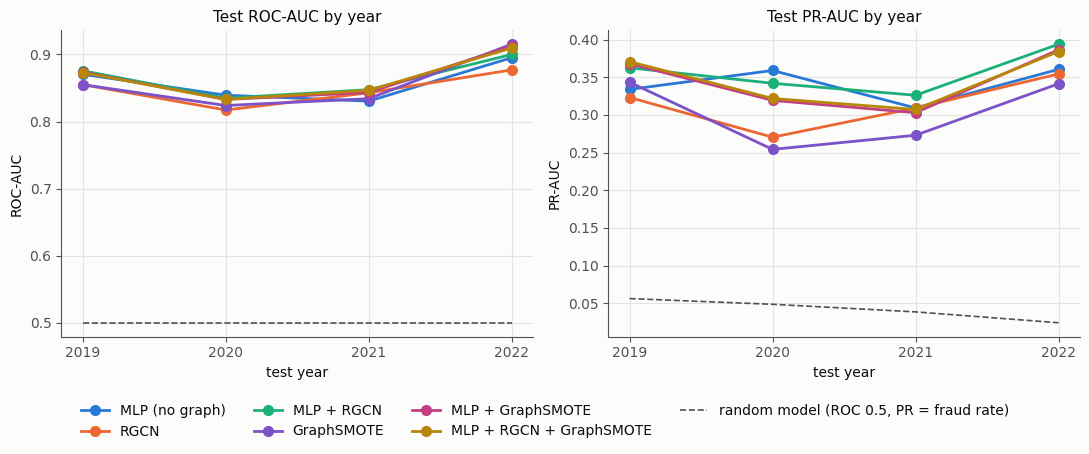

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rate = res[res["model"] == "mlp"].sort_values("test_year")
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for m in MODELS:
        d = res[res["model"] == m].sort_values("test_year")
        ax.plot(d["test_year"], d[metric], marker="o", ms=7, color=COLORS[m], label=NAMES[m])
    if metric == "test_auc":
        baseline(ax, rate["test_year"], [0.5] * len(rate), "random model")
    else:
        baseline(ax, rate["test_year"], rate["test_fraud_rate"], "random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=TEST_YEARS)
handles, names = axes[0].get_legend_handles_labels()
names[-1] = "random model (ROC 0.5, PR = fraud rate)"
# GraphSMOTE >>> legend in two rows now that there are 6 models
fig.legend(handles, names, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.14))
# <<< GraphSMOTE
fig.tight_layout()
fig.savefig(FIG_DIR / "metrics_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

### ROC and precision-recall curves

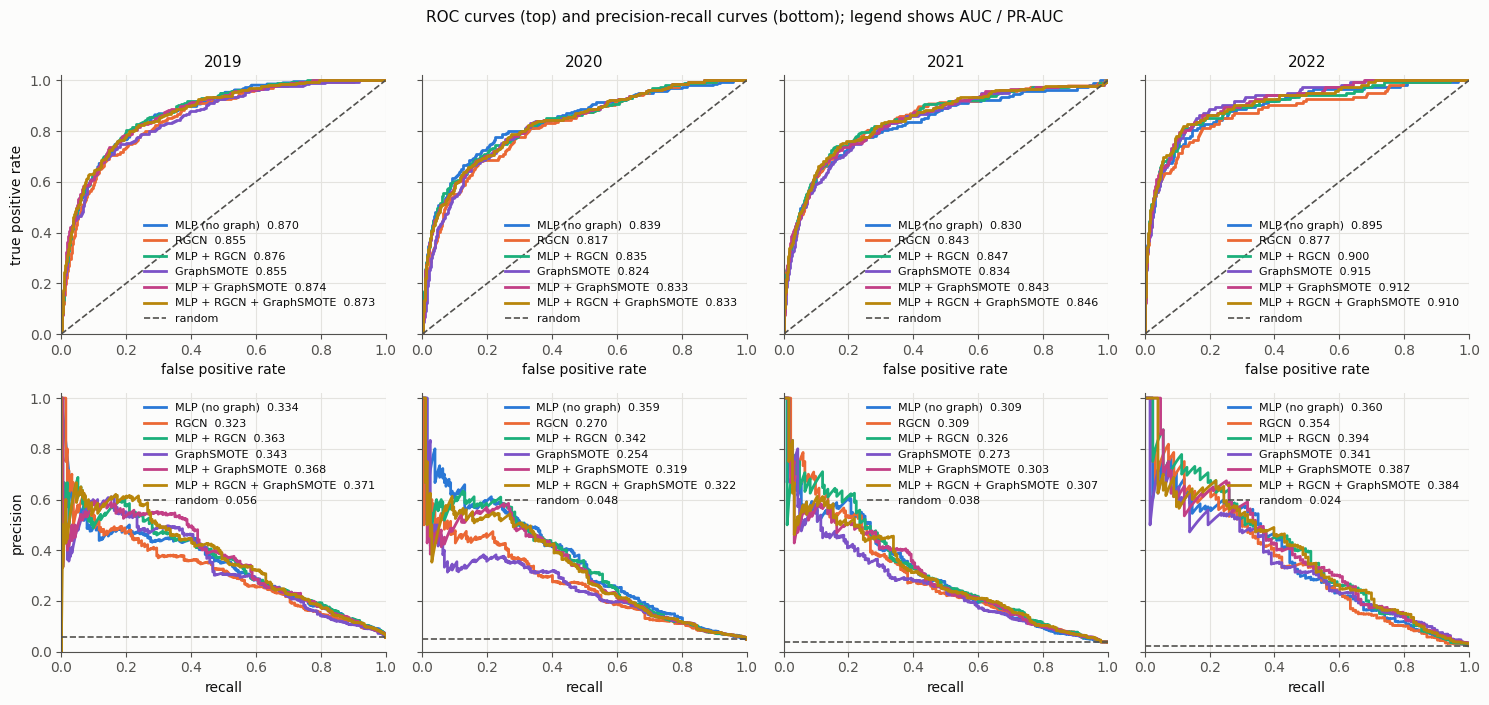

In [31]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for col, yr in enumerate(TEST_YEARS):
    roc_ax, pr_ax = axes[0, col], axes[1, col]
    for m in MODELS:
        g = subset(m, yr)
        fpr, tpr, _ = roc_curve(g["Label"], g["score"])
        prec, rec, _ = precision_recall_curve(g["Label"], g["score"])
        auc, ap = scores(g["Label"], g["score"])
        roc_ax.plot(fpr, tpr, color=COLORS[m], label=f"{NAMES[m]}  {auc:.3f}")
        pr_ax.plot(rec, prec, color=COLORS[m], label=f"{NAMES[m]}  {ap:.3f}")
    rate_yr = g["Label"].mean()
    baseline(roc_ax, [0, 1], [0, 1], "random")
    baseline(pr_ax, [0, 1], [rate_yr, rate_yr], f"random  {rate_yr:.3f}")
    roc_ax.set(title=str(yr), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    roc_ax.xaxis.set_tick_params(labelbottom=True)
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=8, loc="lower right")
    pr_ax.legend(fontsize=8, loc="upper right")
axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom); legend shows AUC / PR-AUC", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Frauds caught when reviewing the top-scored companies

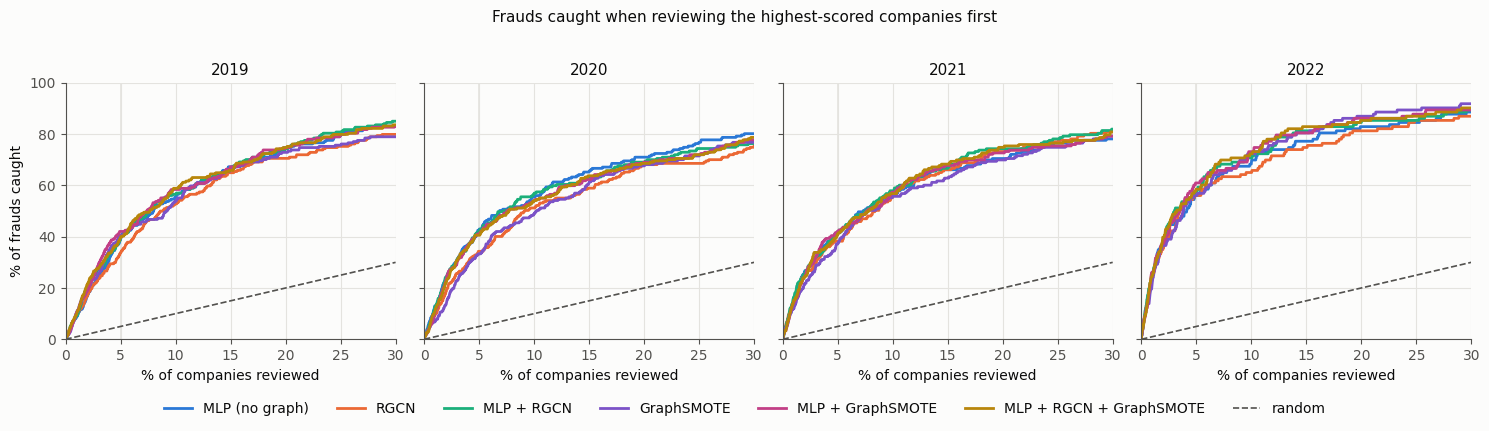

In [32]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, yr in zip(axes, TEST_YEARS):
    for m in MODELS:
        y_sorted = subset(m, yr).sort_values("score", ascending=False)["Label"].to_numpy()
        reviewed = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
        ax.plot(reviewed * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, color=COLORS[m], label=NAMES[m])
    baseline(ax, [0, 30], [0, 30], "random")
    ax.axvline(5, color=GRID, lw=1.2, zorder=0)
    ax.set(title=str(yr), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")
axes[0].set_ylabel("% of frauds caught")
handles, names = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", y=1.02, fontsize=11)
fig.tight_layout()
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIG_DIR / "capture_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Precision and recall at the top 1%, 5% and 10%

In [33]:
rows_k = []
for (m, yr), g in preds_df.groupby(["model", "Year"]):
    g = g.sort_values("score", ascending=False)
    for k in (0.01, 0.05, 0.10):
        top = g.head(int(np.ceil(k * len(g))))
        rows_k.append({"model": NAMES[m],
                       "test_year": yr,
                       "top_%_reviewed": int(k * 100),
                       "precision": top["Label"].mean(),
                       "recall": top["Label"].sum() / g["Label"].sum()})
topk = (pd.DataFrame(rows_k)
        .pivot_table(index=["top_%_reviewed", "test_year"], columns="model", values=["precision", "recall"])
        .round(3))
topk.to_csv(OUT_DIR / "topk_precision_recall.csv")
topk

precision                                  \
model                    GraphSMOTE MLP (no graph) MLP + GraphSMOTE   
top_%_reviewed test_year                                              
1              2019           0.590          0.487            0.590   
               2020           0.349          0.628            0.512   
               2021           0.458          0.583            0.562   
               2022           0.538          0.577            0.615   
5              2019           0.455          0.440            0.471   
               2020           0.322          0.416            0.397   
               2021           0.285          0.318            0.322   
               2022           0.268          0.268            0.292   
10             2019           0.301          0.312            0.327   
               2020           0.237          0.269            0.262   
               2021           0.214          0.216            0.220   
               2022           0.173          0.165            0.175   

                                                                       recall  \
model                    MLP + RGCN MLP + RGCN + GraphSMOTE   RGCN GraphSMOTE   
top_%_reviewed test_year                                                        
1              2019           0.513                   0.564  0.538      0.107   
               2020           0.628                   0.558  0.465      0.072   
               2021           0.625                   0.583  0.542      0.120   
               2022           0.615                   0.596  0.577      0.228   
5              2019           0.445                   0.445  0.377      0.407   
               2020           0.407                   0.393  0.332      0.333   
               2021           0.322                   0.314  0.293      0.372   
               2022           0.276                   0.280  0.268      0.561   
10             2019           0.317                   0.330  0.296      0.537   
               2020           0.276                   0.262  0.248      0.488   
               2021           0.222                   0.218  0.214      0.557   
               2022           0.169                   0.173  0.156      0.724   

                                                                     \
model                    MLP (no graph) MLP + GraphSMOTE MLP + RGCN   
top_%_reviewed test_year                                              
1              2019               0.089            0.107      0.093   
               2020               0.130            0.106      0.130   
               2021               0.153            0.148      0.164   
               2022               0.244            0.260      0.260   
5              2019               0.393            0.421      0.397   
               2020               0.430            0.411      0.420   
               2021               0.415            0.421      0.421   
               2022               0.561            0.610      0.577   
10             2019               0.556            0.584      0.565   
               2020               0.556            0.541      0.570   
               2021               0.563            0.574      0.579   
               2022               0.691            0.732      0.707   

                                                         
model                    MLP + RGCN + GraphSMOTE   RGCN  
top_%_reviewed test_year                                 
1              2019                        0.103  0.098  
               2020                        0.116  0.097  
               2021                        0.153  0.142  
               2022                        0.252  0.244  
5              2019                        0.397  0.336  
               2020                        0.406  0.343  
               2021                        0.410  0.383  
               2022                        0.585  0.561  
10             2019                     

### Training curves

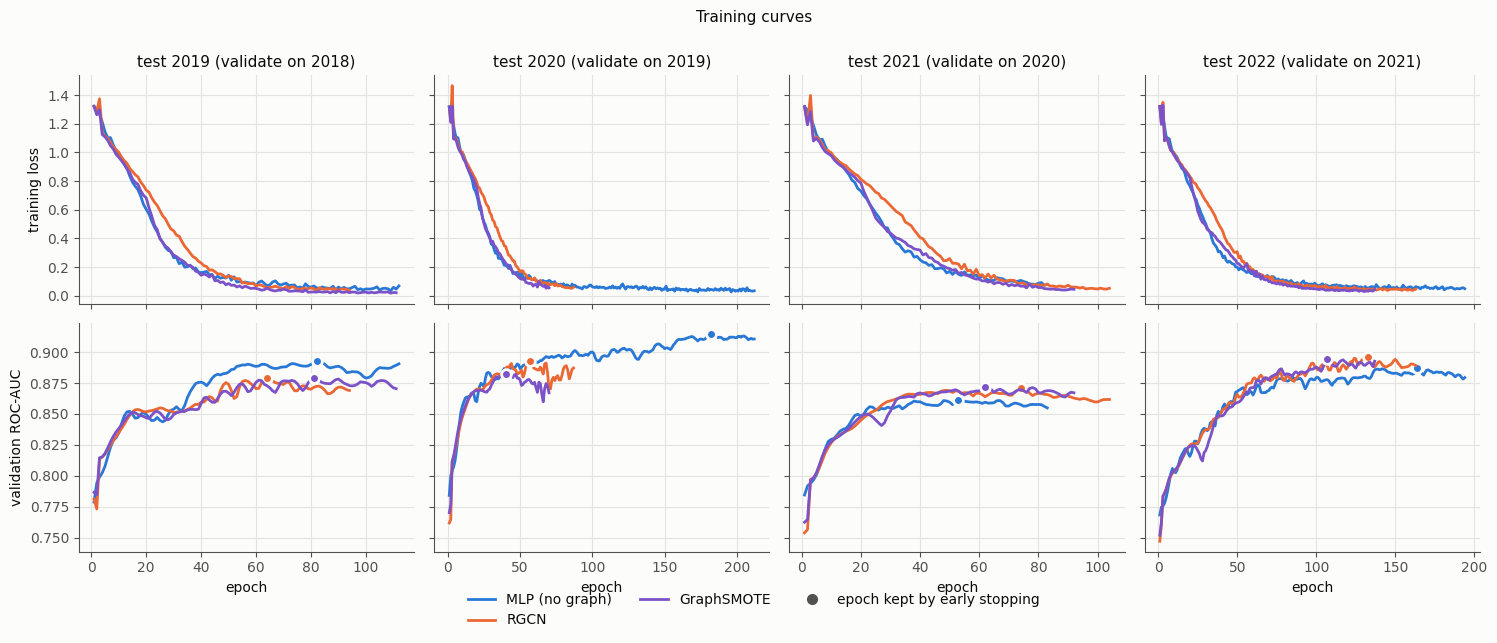

In [34]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 6), sharex="col", sharey="row")
for col, yr in enumerate(TEST_YEARS):
    for m in TRAINED:
        h = hist_df[(hist_df["model"] == m) & (hist_df["test_year"] == yr)]
        best = h.loc[h["val_auc"].idxmax()]
        # GraphSMOTE >>> GraphSMOTE only keeps checkpoints from after its warm-up
        if m == "gsmote":
            best = h.loc[h.loc[h["epoch"] > GSMOTE_KW["warmup"], "val_auc"].idxmax()]
        # <<< GraphSMOTE
        axes[0, col].plot(h["epoch"], h["loss"], color=COLORS[m])
        axes[1, col].plot(h["epoch"], h["val_auc"], color=COLORS[m])
        axes[1, col].plot(best["epoch"], best["val_auc"], "o", ms=7, color=COLORS[m], markeredgecolor=SURFACE, markeredgewidth=2)
    axes[0, col].set_title(f"test {yr} (validate on {yr - 1})")
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel("validation ROC-AUC")

handles = [Line2D([], [], color=COLORS[m], label=NAMES[m]) for m in TRAINED]
handles.append(Line2D([], [], ls="", marker="o", ms=7, color=MUTED, label="epoch kept by early stopping"))
fig.suptitle("Training curves", y=1.0, fontsize=11)
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.savefig(FIG_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Confusion matrices

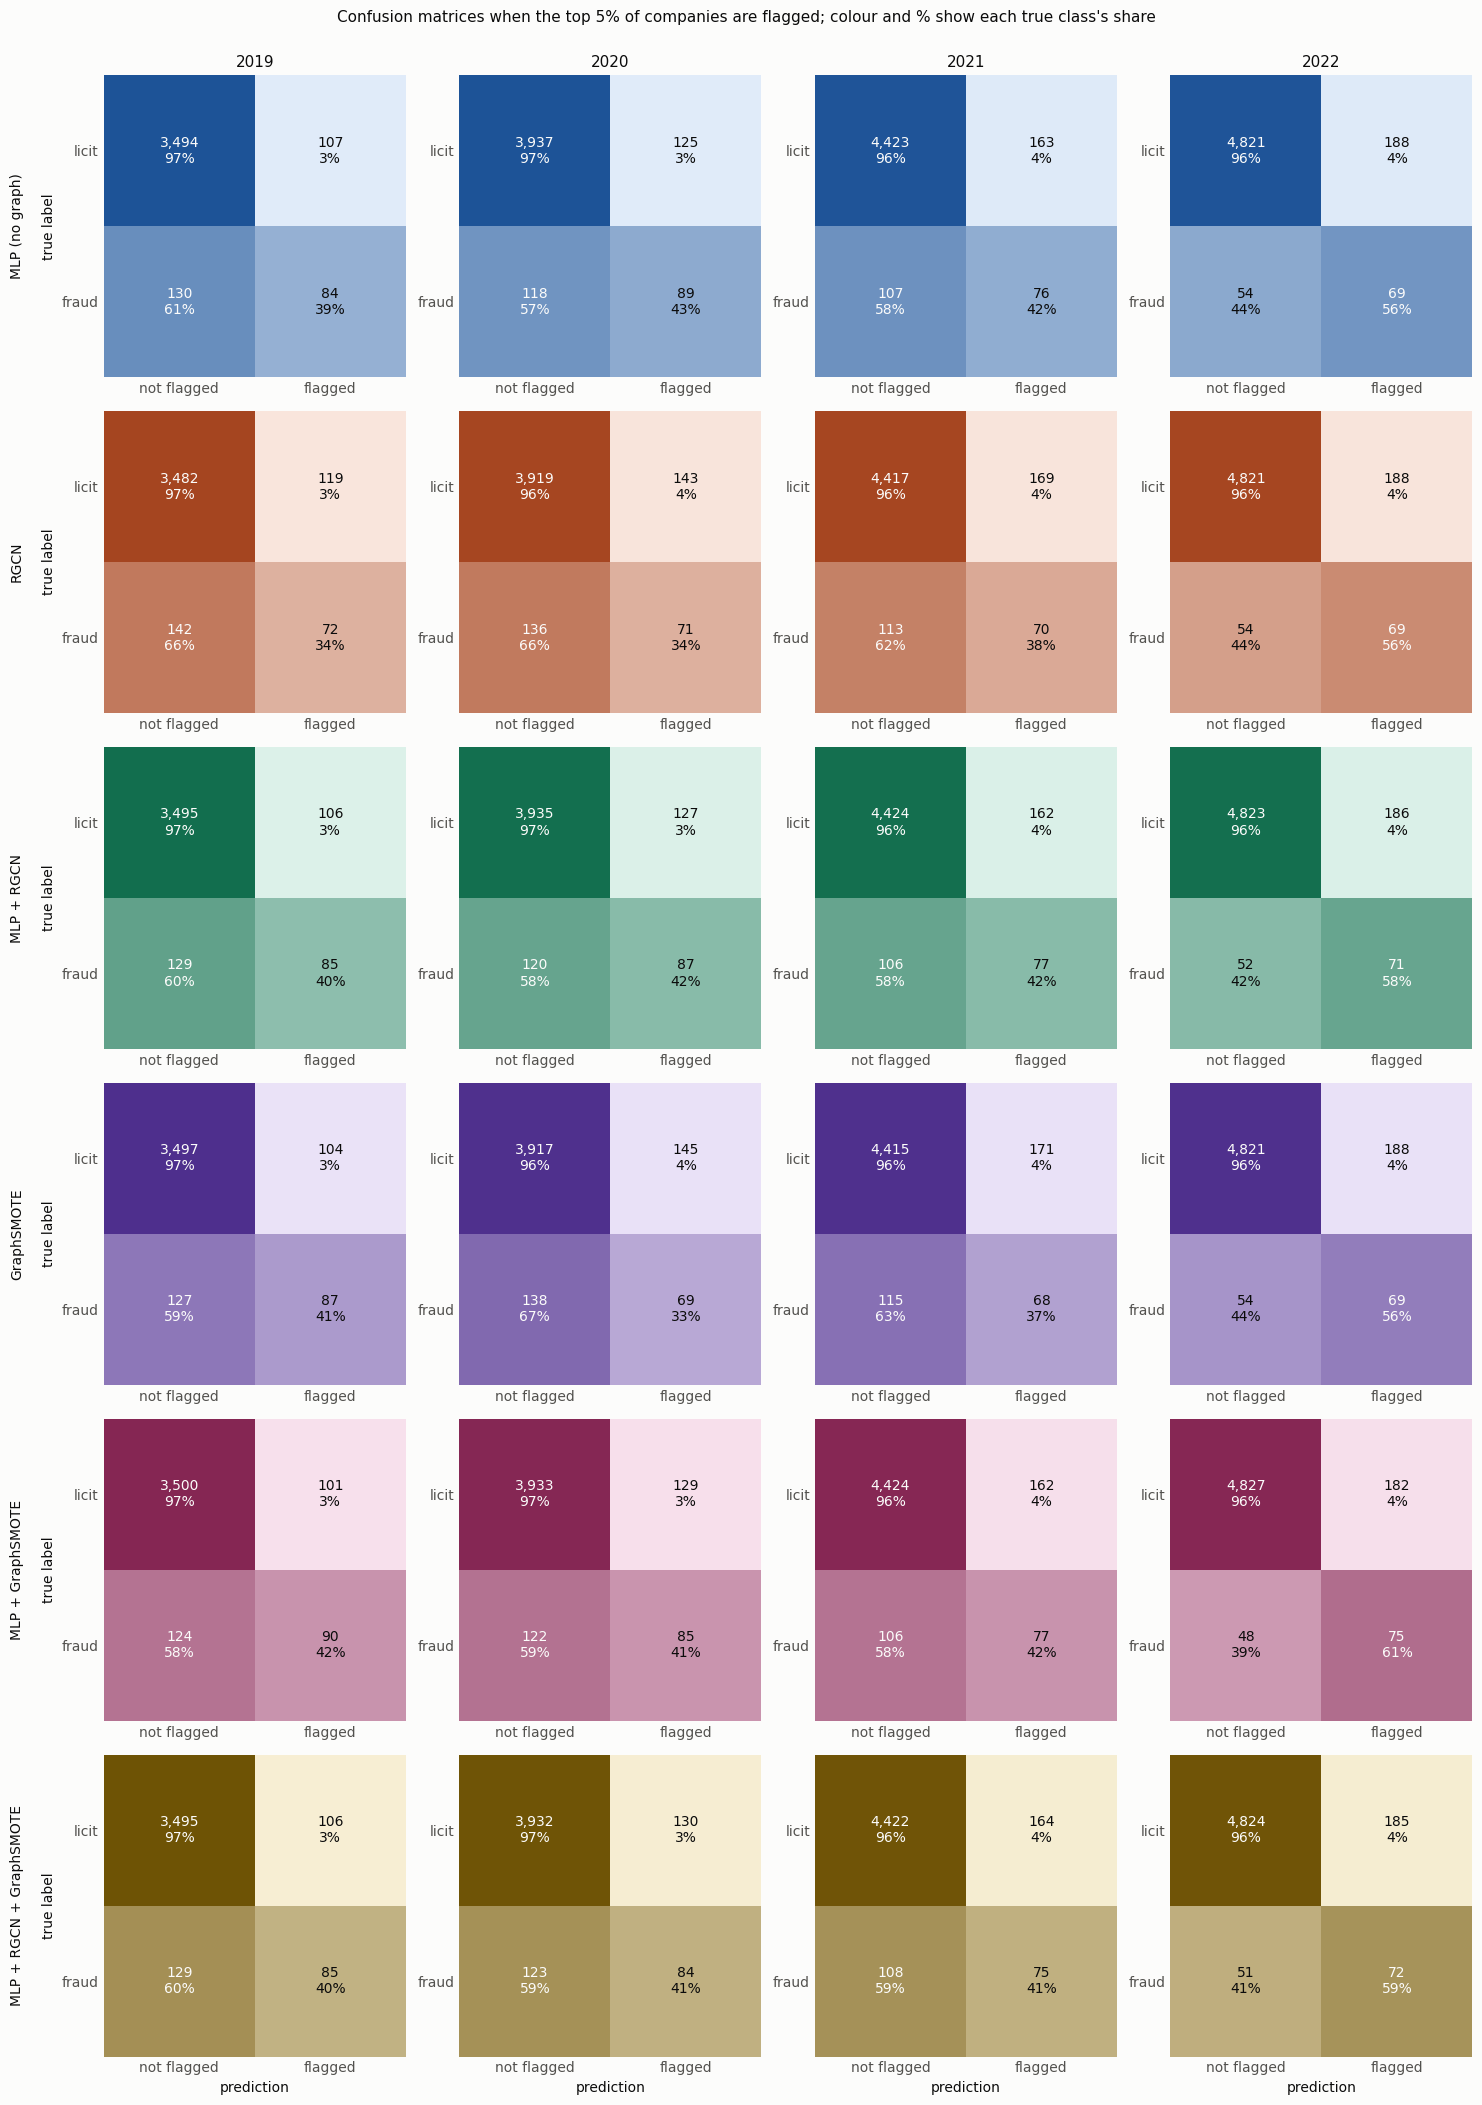

,model,test_year,TP,FP,FN,TN,precision,recall
0,MLP (no graph),2019,84,107,130,3494,0.440,0.393
1,MLP (no graph),2020,89,125,118,3937,0.416,0.430
2,MLP (no graph),2021,76,163,107,4423,0.318,0.415
3,MLP (no graph),2022,69,188,54,4821,0.268,0.561
4,RGCN,2019,72,119,142,3482,0.377,0.336
5,RGCN,2020,71,143,136,3919,0.332,0.343
6,RGCN,2021,70,169,113,4417,0.293,0.383
7,RGCN,2022,69,188,54,4821,0.268,0.561
8,MLP + RGCN,2019,85,106,129,3495,0.445,0.397
9,MLP + RGCN,2020,87,127,120,3935,0.407,0.420


In [35]:
FLAG_SHARE = 0.05
RAMPS = {"mlp": ["#e6f0fc", "#184f95"], "rgcn": ["#fcebe3", "#a3401a"], "ens": ["#e2f5ee", "#0d6b4a"]}
RAMPS.update(GSMOTE_RAMPS)  # GraphSMOTE

fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.5 * len(MODELS)))
cm_rows = []
for r, m in enumerate(MODELS):
    cmap = LinearSegmentedColormap.from_list(m, RAMPS[m])
    for c, yr in enumerate(TEST_YEARS):
        g = subset(m, yr)
        n_flag = int(np.ceil(FLAG_SHARE * len(g)))
        flagged = np.zeros(len(g), dtype=int)
        flagged[np.argsort(-g["score"].to_numpy())[:n_flag]] = 1
        cm = confusion_matrix(g["Label"], flagged, labels=[0, 1])
        share = cm / cm.sum(axis=1, keepdims=True)

        ax = axes[r, c]
        ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=10, color=SURFACE if share[i, j] > 0.5 else INK)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.tick_params(length=0)
        if r == 0:
            ax.set_title(str(yr))
        if c == 0:
            ax.set_ylabel(f"{NAMES[m]}\n\ntrue label")
        if r == len(MODELS) - 1:
            ax.set_xlabel("prediction")

        tn, fp, fn, tp = cm.ravel()
        cm_rows.append({"model": NAMES[m],
                        "test_year": yr,
                        "TP": tp,
                        "FP": fp,
                        "FN": fn,
                        "TN": tn,
                        "precision": tp / (tp + fp),
                        "recall": tp / (tp + fn)})

fig.suptitle(f"Confusion matrices when the top {FLAG_SHARE:.0%} of companies are flagged; colour and % show each true class's share", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

cm_table = pd.DataFrame(cm_rows).round(3)
cm_table.to_csv(OUT_DIR / "confusion_matrices.csv", index=False)
cm_table

### GraphSMOTE: frauds caught in the top 5%, by model


In [36]:
caught = cm_table.pivot(index="test_year", columns="model", values="TP")
caught.loc["total"] = caught.sum()
caught = caught[[NAMES[m] for m in MODELS]]
caught.insert(0, "frauds", list(cm_table.groupby("test_year")[["TP", "FN"]].first().sum(axis=1)) + [None])
caught.loc["total", "frauds"] = caught["frauds"].iloc[:-1].sum()
caught.astype(int)

model,frauds,MLP (no graph),RGCN,MLP + RGCN,GraphSMOTE,MLP + GraphSMOTE,MLP + RGCN + GraphSMOTE
test_year,,,,,,,
2019,214,84,72,85,87,90,85
2020,207,89,71,87,69,85,84
2021,183,76,70,77,68,77,75
2022,123,69,69,71,69,75,72
total,727,318,282,320,293,327,316
